# Calibrate the fine-masking gate (tau) and the image score — validation only

**Why this notebook exists.** Notebook 03 showed three things:

1. With the default gate `tau = 0.5`, the fine pass fired on at most ~1% of test images, so "adaptive" masking behaved like coarse-only masking.
2. The image score is `max` over the 196 patch scores, so one noisy patch can decide the whole image.
3. Capsule is at chance level for both predictors.

This notebook tests the two cheapest fixes for (1) and (2). Neither needs retraining.

| Fix | What changes | Set from |
| --- | --- | --- |
| **Calibrated `tau`** | The fine pass fires on a chosen small share of *normal* tokens instead of never | Nominal **validation** images only |
| **Top-k image score** | Image score = mean of the `k` highest patch scores instead of the single highest | Declared up front (not tuned) |

**Rules this notebook follows (so the numbers mean something)**

1. Part A uses **only nominal validation images** (no defects, no test data) to set `tau`.
2. Part B scores the test set. The *primary* setting (`PRIMARY_*` below) is declared before any test result is seen.
3. `lambda` cannot be calibrated: it trades coarse against fine evidence, and that trade-off only shows up on defective images. It stays at 1.0; other values are a sensitivity check, not a selection.
4. Every other row in the grids is for understanding only. Picking the best-looking test row would be tuning on the test set.

Outputs go to `results/calibration/` (set `OVERWRITE = True` to replace them). The validation latent cache is built once under `data/cache/latents` if it is missing.

## 1. Imports and configuration

Everything you may want to change is in this cell. The "declared before looking" block is the experiment design; change it only before running, never after seeing test numbers.

In [1]:
import hashlib
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
PREDICTOR_SET = 'baseline'  # 'baseline' or 'augmented'
CHECKPOINT_ROOT = {
    'baseline': PROJECT_ROOT / 'checkpoints' / 'predictors',
    'augmented': PROJECT_ROOT / 'checkpoints' / 'predictors_augmented',
}[PREDICTOR_SET]

ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
OFFICIAL_IJEPA_ROOT = PROJECT_ROOT / 'external' / 'ijepa'
VAL_CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents'
TEST_CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents_test'
OUTPUT_ROOT = Path(os.environ.get('CALIBRATION_OUTPUT', PROJECT_ROOT / 'results' / 'calibration'))
FIGURE_ROOT = OUTPUT_ROOT / 'figures'
OVERWRITE = False

MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION = float(DATA_CONFIG['nominal_split']['val_fraction'])
SPLIT_SEED = int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Declared before looking at any test result ---------------------------------
TOKEN_QUANTILES = (0.90, 0.95, 0.99, 0.995)  # candidate gates: fire on ~(1-q) of normal tokens
PRIMARY_QUANTILE = 0.99                      # the calibrated gate we commit to
K_VALUES = (1, 3, 5, 10, 20)                 # k=1 is the original max score
PRIMARY_K = 5                                # ~2.5% of the 196 tokens
LAMBDAS = (0.0, 0.5, 1.0, 2.0)               # sensitivity only; lambda=0 means coarse-only
PRIMARY_LAMBDA = 1.0
TARGET_FPR = 0.05                            # nominal-validation false-positive target
N_BOOTSTRAP = 1000
# ----------------------------------------------------------------------------------

print(f'Project: {PROJECT_ROOT}\nDevice: {DEVICE}\nPredictors: {PREDICTOR_SET} ({CHECKPOINT_ROOT})')
print(f'Outputs: {OUTPUT_ROOT}')

Project: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD
Device: cuda
Predictors: baseline (c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors)
Outputs: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\calibration


## 2. Load splits, encoder identity and predictors

The nominal train/validation split uses the same fraction and seed as training, so the validation images here are exactly the ones the predictors were *not* trained on. The encoder SHA-256 is checked against each checkpoint, so a mismatched predictor fails loudly.

In [2]:
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.evaluation.metrics import aupro, calibrate_image_threshold, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, ENCODER_NAME, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import (
    MaskedLatentScorer,
    load_masking_settings,
    load_predictor_checkpoint_with_provenance,
)
from ijepa_ad.masking.score_maps import upsample_patch_scores

if not ENCODER_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Encoder checkpoint missing: {ENCODER_CHECKPOINT}')
ENCODER_SHA256 = compute_file_sha256(ENCODER_CHECKPOINT)
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
print(f'Encoder SHA-256: {ENCODER_SHA256}')
print(f'Masking settings from YAML: {MASKING_SETTINGS}')

DATASET_ROOTS = {}
for category in CATEGORIES:
    options = (
        PROJECT_ROOT / DATA_CONFIG['root'],
        PROJECT_ROOT / 'dataset',
        PROJECT_ROOT / 'dataset' / category,
    )
    root = next((r for r in options if (r / category / 'train').is_dir()), None)
    if root is None:
        raise FileNotFoundError(f'MVTec folders for {category} not found in {options}')
    DATASET_ROOTS[category] = root

SPLITS, PREDICTORS, PROVENANCE = {}, {}, {}
for category in CATEGORIES:
    train_ds, test_ds = validate_category_splits(DATASET_ROOTS[category], category)
    nominal = split_nominal_train_val(
        train_ds.samples,
        val_fraction=VAL_FRACTION,
        seed=SPLIT_SEED,
        min_train=int(DATA_CONFIG['nominal_split']['min_train']),
        min_val=int(DATA_CONFIG['nominal_split']['min_val']),
    )
    SPLITS[category] = {'train': train_ds, 'test': test_ds, 'nominal': nominal}
    path = CHECKPOINT_ROOT / f'{category}_cosine.pt'
    if not path.is_file():
        raise FileNotFoundError(f'Predictor checkpoint missing (no substitution): {path}')
    PREDICTORS[category], PROVENANCE[category] = load_predictor_checkpoint_with_provenance(
        path, category=category, encoder_sha256=ENCODER_SHA256, device=DEVICE
    )
    print(
        f'{category}: val images={len(nominal.val)}, test images={len(test_ds)}, '
        f'mask_strategy={PROVENANCE[category]["mask_strategy"]}, status={PROVENANCE[category]["status"]}'
    )

Encoder SHA-256: a373c7b16165092e29bd5714c6ce79c574c4a52b01b64bf4c82dc81e6a82cf0b
Masking settings from YAML: {'coarse_size': 4, 'fine_size': 1, 'threshold': 0.5, 'lam': 1.0}
bottle: val images=21, test images=83, mask_strategy=inference_aligned, status=complete
capsule: val images=22, test images=132, mask_strategy=inference_aligned, status=complete
hazelnut: val images=39, test images=110, mask_strategy=inference_aligned, status=complete


## 3. Validation and test latent caches

The encoder is frozen, so each image only needs to be encoded once. The **test** cache already exists from notebook 03. The **validation** cache is built the first time (it also writes the train latents, which notebook 01 reuses). This step loads the 16 GB encoder, so it can take a few minutes the first time and is skipped afterwards.

In [3]:
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.caching.cli import CacheRunConfig, run_cache_generation
from ijepa_ad.caching.latent_cache import CacheNotFoundError
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset

PREPROCESSING = PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size']))
PREPROCESSING_SPEC = PreprocessingSpec.from_config(PREPROCESSING)


def expectations(category, split, samples):
    return CacheExpectations(
        category=category,
        split=split,
        encoder_name=ENCODER_NAME,
        checkpoint_sha256=ENCODER_SHA256,
        patch_size=PATCH_SIZE,
        embedding_dim=EMBEDDING_DIM,
        preprocessing=PREPROCESSING_SPEC,
        sample_ids=tuple(s.image_id for s in samples),
        num_tokens=NUM_TOKENS,
    )


def load_val(category):
    return load_cached_latent_dataset(
        VAL_CACHE_ROOT,
        expectations(category, 'val', SPLITS[category]['nominal'].val),
        samples=SPLITS[category]['train'].samples,
    )


def load_test(category):
    return load_cached_latent_dataset(
        TEST_CACHE_ROOT,
        expectations(category, 'test', SPLITS[category]['test'].samples),
        samples=SPLITS[category]['test'].samples,
    )


missing_val = []
for category in CATEGORIES:
    try:
        load_val(category)
    except CacheNotFoundError:
        missing_val.append(category)
for category in missing_val:
    summary = run_cache_generation(
        CacheRunConfig(
            dataset_root=DATASET_ROOTS[category],
            cache_root=VAL_CACHE_ROOT,
            categories=(category,),
            purpose='nominal',
            batch_size=8,
            device=DEVICE,
            val_fraction=VAL_FRACTION,
            seed=SPLIT_SEED,
            image_size=PREPROCESSING.image_size,
            checkpoint=ENCODER_CHECKPOINT,
            official_repo=OFFICIAL_IJEPA_ROOT,
            encoder_name=ENCODER_NAME,
        )
    )
    if not summary.ok:
        raise RuntimeError(f'Validation cache build failed for {category}: {summary.to_dict()}')
    print(f'{category}: built nominal caches')

VAL_DATASETS = {c: load_val(c) for c in CATEGORIES}
try:
    TEST_DATASETS = {c: load_test(c) for c in CATEGORIES}
except CacheNotFoundError as error:
    raise FileNotFoundError(
        'The test latent cache is missing. Run notebook 03 first (it builds data/cache/latents_test).'
    ) from error
for category in CATEGORIES:
    val_ids = {s.image_id for s in VAL_DATASETS[category]}
    test_ids = {s.image_id for s in TEST_DATASETS[category]}
    if val_ids & test_ids:
        raise ValueError(f'Validation/test overlap in {category}')
    print(f'{category}: val={len(VAL_DATASETS[category])} (all nominal), test={len(TEST_DATASETS[category])}')

bottle: val=21 (all nominal), test=83
capsule: val=22 (all nominal), test=132
hazelnut: val=39 (all nominal), test=110


## Part A — Calibrate `tau` on nominal validation images only

**How the gate works** (from `MaskedLatentScorer`):

1. The coarse pass hides each 4x4 block of tokens (16 blocks) and asks the predictor to reconstruct them. Each token gets a discrepancy `1 - cos(predicted, actual)`.
2. Every token's **region score** is the mean discrepancy of its coarse block.
3. Each single-token (1x1) fine candidate whose region score is `>= tau` gets its own fine pass.

So the fine pass depends **only on coarse region scores**, and we can study it on normal images alone. A trained predictor reproduces normal tokens well, so normal region scores should be small. If they all sit far below `tau = 0.5`, the gate can never open. Setting `tau` to a high quantile of the *normal* region scores makes the fine pass fire on roughly `(1 - q)` of normal tokens, while a defect, whose coarse score is above the normal range, opens it far more often.

Quantiles are taken over all validation tokens pooled together (21-39 images x 196 tokens), which is far more stable than a quantile over one score per image.

In [4]:
def run_scorer(predictor, dataset, mode, threshold):
    scorer = MaskedLatentScorer(predictor, **{**MASKING_SETTINGS, 'threshold': float(threshold)})
    coarse, fine, work = [], [], []
    for sample in dataset:
        result = scorer.score(sample.latent.unsqueeze(0).to(DEVICE), mode=mode)
        coarse.append(result.coarse_scores.detach().cpu())
        fine.append(result.fine_scores.detach().cpu())
        work.append(result.evaluated_regions)
    return torch.stack(coarse), torch.stack(fine), np.asarray(work), scorer


def region_scores(scorer, coarse):
    out = torch.zeros_like(coarse)
    for window in scorer.coarse.windows():
        idx = list(window.token_indices)
        out[:, idx] = coarse[:, idx].mean(dim=1, keepdim=True)
    return out


DEFAULT_TAU = MASKING_SETTINGS['threshold']
VAL = {}
rows = []
for category in CATEGORIES:
    coarse, _, _, scorer = run_scorer(PREDICTORS[category], VAL_DATASETS[category], 'fixed', DEFAULT_TAU)
    region = region_scores(scorer, coarse)
    pooled = region.flatten().numpy()
    taus = {q: float(np.quantile(pooled, q)) for q in TOKEN_QUANTILES}
    VAL[category] = {'region': region, 'taus': taus, 'n_coarse': len(scorer.coarse.windows())}
    options = [('default', DEFAULT_TAU)] + [(f'q{q}', t) for q, t in taus.items()]
    for name, tau in options:
        gate = region >= tau
        rows.append({
            'category': category,
            'gate': name,
            'tau': tau,
            'nominal_fine_windows_per_image': gate.sum(dim=1).float().mean().item(),
            'nominal_images_triggering_fine_pass_%': 100 * gate.any(dim=1).float().mean().item(),
        })
    print(
        f'{category}: normal region score  median={np.median(pooled):.4f}  '
        f'p99={np.quantile(pooled, 0.99):.4f}  max={pooled.max():.4f}   (default tau={DEFAULT_TAU})'
    )
gate_df = pd.DataFrame(rows)
display(gate_df.round(4))

c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(


bottle: normal region score  median=0.0527  p99=0.1575  max=0.2429   (default tau=0.5)
capsule: normal region score  median=0.1320  p99=0.2639  max=0.2847   (default tau=0.5)
hazelnut: normal region score  median=0.2016  p99=0.3500  max=0.4218   (default tau=0.5)


,category,gate,tau,nominal_fine_windows_per_image,nominal_images_triggering_fine_pass_%
0,bottle,default,0.5000,0.0000,0.0000
1,bottle,q0.9,0.0981,19.8095,85.7143
2,bottle,q0.95,0.1232,9.9048,61.9048
3,bottle,q0.99,0.1575,2.2857,19.0476
4,bottle,q0.995,0.1840,1.1429,14.2857
5,capsule,default,0.5000,0.0000,0.0000
6,capsule,q0.9,0.2065,19.6364,90.9091
7,capsule,q0.95,0.2253,9.8182,68.1818
8,capsule,q0.99,0.2639,2.1818,22.7273
9,capsule,q0.995,0.2820,1.0909,13.6364


**How to read the table.** `gate = default` is the original `tau = 0.5`. If its "fine windows per image" is 0 and "images triggering" is 0%, the original gate never opens even on normal images, and certainly cannot be tuned to the data. The `q...` rows show what a data-driven gate does on normal images: `q0.99` should add roughly 2 fine windows per normal image (1% of 196 tokens). That is the *compute cost on normal images*; defects raise it.

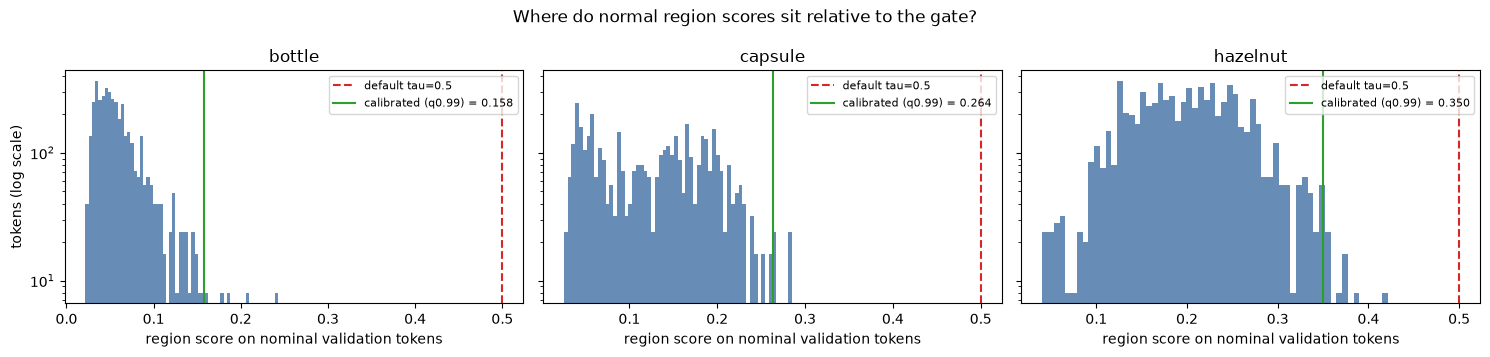

In [5]:
def make_taus(category):
    options = {'default': DEFAULT_TAU}
    options.update({f'q{q}': t for q, t in VAL[category]['taus'].items()})
    return options


PRIMARY_KEY = f'q{PRIMARY_QUANTILE}'

fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(5 * len(CATEGORIES), 3.6), sharey=True)
for ax, category in zip(np.atleast_1d(axes), CATEGORIES):
    pooled = VAL[category]['region'].flatten().numpy()
    ax.hist(pooled, bins=60, color='#4C78A8', alpha=0.85)
    ax.set_yscale('log')
    ax.axvline(DEFAULT_TAU, color='#D62728', linestyle='--', label=f'default tau={DEFAULT_TAU}')
    ax.axvline(VAL[category]['taus'][PRIMARY_QUANTILE], color='#2CA02C', label=f'calibrated ({PRIMARY_KEY}) = {VAL[category]["taus"][PRIMARY_QUANTILE]:.3f}')
    ax.set_title(category)
    ax.set_xlabel('region score on nominal validation tokens')
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel('tokens (log scale)')
fig.suptitle('Where do normal region scores sit relative to the gate?')
fig.tight_layout()
plt.show()

## Part B — Score the test set once and compare

We run the predictor on the test cache for each gate (default, the four calibrated quantiles, and a dense reference), keeping the raw coarse and fine patch scores. That lets us recombine them for any `lambda` or image score without re-running the model.

**Image-score variants**
* `max` (k=1): the original rule. One noisy patch can dominate.
* `top-k mean`: average of the `k` largest patch scores. A real defect usually lights up several neighbouring patches, noise usually does not, so this is often more stable. `k` was declared up front.

**Reference rows** (for context, not candidates): `fixed` = coarse pass only (`lambda = 0`), `dense` = a fine pass over all 196 tokens (the compute ceiling).

In [6]:
def load_ground_truth(annotation):
    if annotation.mask_path is None:
        with Image.open(annotation.image_path) as image:
            width, height = image.size
        return np.zeros((height, width), dtype=bool)
    with Image.open(annotation.mask_path) as mask_image:
        return np.asarray(mask_image.convert('L')) > 0


TEST = {}
for category in CATEGORIES:
    started = time.perf_counter()
    dataset = TEST_DATASETS[category]
    labels, masks = [], []
    for sample in dataset:
        labels.append(int(sample.annotation.label != 'good'))
        masks.append(load_ground_truth(sample.annotation))
    runs = {}
    for name, tau in make_taus(category).items():
        coarse, fine, work, scorer = run_scorer(PREDICTORS[category], dataset, 'adaptive', tau)
        runs[name] = {'coarse': coarse, 'fine': fine, 'work': work, 'tau': tau}
    coarse, fine, work, scorer = run_scorer(PREDICTORS[category], dataset, 'dense', DEFAULT_TAU)
    runs['dense'] = {'coarse': coarse, 'fine': fine, 'work': work, 'tau': None}
    TEST[category] = {'labels': np.asarray(labels), 'masks': masks, 'runs': runs}
    TEST[category]['n_coarse'] = len(scorer.coarse.windows())
    print(f'{category}: scored {len(labels)} test images with {len(runs)} gate settings in {time.perf_counter() - started:.0f}s')


def patch_scores(run, lam):
    return run['coarse'] + lam * run['fine']


def image_scores(patch, k):
    return patch.topk(k, dim=1).values.mean(dim=1).numpy()

bottle: scored 83 test images with 6 gate settings in 49s
capsule: scored 132 test images with 6 gate settings in 55s
hazelnut: scored 110 test images with 6 gate settings in 52s


In [7]:
grid_rows = []
for category in CATEGORIES:
    data = TEST[category]
    for name, run in data['runs'].items():
        lams = (1.0,) if name == 'dense' else LAMBDAS
        triggered = float(np.mean(run['work'] > data['n_coarse'])) if name != 'dense' else float('nan')
        for lam in lams:
            patch = patch_scores(run, lam)
            for k in K_VALUES:
                grid_rows.append({
                    'category': category,
                    'gate': name,
                    'tau': run['tau'],
                    'lambda': lam,
                    'k': k,
                    'image_auroc': image_auroc(data['labels'], image_scores(patch, k)),
                    'masks_per_image': float(np.mean(run['work'])),
                    'fine_trigger_rate': triggered,
                })
grid_df = pd.DataFrame(grid_rows)

print('Image AUROC at lambda=1.0: rows = gate, columns = k (k=1 is the original max score)')
for category in CATEGORIES:
    view = grid_df[(grid_df.category == category) & (grid_df['lambda'] == PRIMARY_LAMBDA)]
    table = view.pivot_table(index='gate', columns='k', values='image_auroc')
    table['masks/img'] = view.groupby('gate')['masks_per_image'].first()
    table['trigger rate'] = view.groupby('gate')['fine_trigger_rate'].first()
    print(f'\n{category}')
    display(table.round(4))

Image AUROC at lambda=1.0: rows = gate, columns = k (k=1 is the original max score)

bottle


k,1,3,5,10,20,masks/img,trigger rate
gate,,,,,,,
default,0.9246,0.9516,0.9563,0.9683,0.9738,16.1928,0.0120
dense,0.9278,0.9548,0.9571,0.9690,0.9738,196.0000,NaN
q0.9,0.9825,0.9841,0.9865,0.9833,0.9833,105.5904,0.9759
q0.95,0.9500,0.9587,0.9675,0.9714,0.9722,80.2892,0.8675
q0.99,0.9508,0.9524,0.9548,0.9635,0.9690,58.2169,0.7349
q0.995,0.9548,0.9635,0.9651,0.9706,0.9754,44.6747,0.6145



capsule


k,1,3,5,10,20,masks/img,trigger rate
gate,,,,,,,
default,0.5217,0.5122,0.5277,0.5592,0.6434,16.0000,0.0000
dense,0.5154,0.5253,0.5337,0.5915,0.6492,196.0000,NaN
q0.9,0.4483,0.5130,0.5381,0.5748,0.5975,48.6667,0.9470
q0.95,0.4711,0.5010,0.5181,0.5437,0.5596,36.3030,0.7197
q0.99,0.5229,0.5309,0.5437,0.5648,0.6079,22.9697,0.3258
q0.995,0.5536,0.5393,0.5381,0.5489,0.6231,19.6970,0.1591



hazelnut


k,1,3,5,10,20,masks/img,trigger rate
gate,,,,,,,
default,0.8021,0.8975,0.9304,0.9507,0.9521,16.1455,0.0091
dense,0.8193,0.8993,0.9321,0.9482,0.9532,196.0000,NaN
q0.9,0.8457,0.8557,0.8464,0.8343,0.8354,51.1273,0.9455
q0.95,0.8129,0.8271,0.8229,0.8268,0.8336,33.6727,0.6727
q0.99,0.8114,0.8721,0.8896,0.9093,0.9125,22.9091,0.3000
q0.995,0.8229,0.8961,0.9175,0.9314,0.9279,20.2182,0.2000


## Pixel-level metrics for the reference configurations

`k` only changes the image score, not the localization map, so pixel metrics depend on the gate and `lambda` only. We compute them for four settings: coarse-only, the original gate, the calibrated gate, and dense. AUPRO uses 200 thresholds, like notebook 03.

In [8]:
def pixel_metrics(patch, masks):
    maps = [
        upsample_patch_scores(p, output_size=m.shape)[0, 0].numpy().astype(np.float32)
        for p, m in zip(patch, masks)
    ]
    return pixel_auroc(maps, masks), aupro(maps, masks, num_thresholds=200)


pixel_rows = []
for category in CATEGORIES:
    data = TEST[category]
    configs = [
        ('fixed (coarse only)', 'default', 0.0),
        ('adaptive, default tau', 'default', PRIMARY_LAMBDA),
        (f'adaptive, calibrated tau ({PRIMARY_KEY})', PRIMARY_KEY, PRIMARY_LAMBDA),
        ('dense (reference)', 'dense', 1.0),
    ]
    for label, key, lam in configs:
        run = data['runs'][key]
        pa, ap = pixel_metrics(patch_scores(run, lam), data['masks'])
        pixel_rows.append({
            'category': category,
            'config': label,
            'pixel_auroc': pa,
            'aupro': ap,
            'masks_per_image': float(np.mean(run['work'])) if key != 'default' or lam > 0 else float(data['n_coarse']),
        })
pixel_df = pd.DataFrame(pixel_rows)
display(pixel_df.round(4))

,category,config,pixel_auroc,aupro,masks_per_image
0,bottle,fixed (coarse only),0.9297,0.7663,16.0000
1,bottle,"adaptive, default tau",0.9295,0.7657,16.1928
2,bottle,"adaptive, calibrated tau (q0.99)",0.9262,0.7324,58.2169
3,bottle,dense (reference),0.9284,0.7617,196.0000
4,capsule,fixed (coarse only),0.6845,0.0981,16.0000
5,capsule,"adaptive, default tau",0.6845,0.0981,16.0000
6,capsule,"adaptive, calibrated tau (q0.99)",0.6998,0.1030,22.9697
7,capsule,dense (reference),0.7063,0.1114,196.0000
8,hazelnut,fixed (coarse only),0.9067,0.5777,16.0000
9,hazelnut,"adaptive, default tau",0.9067,0.5774,16.1455


## The 2 x 2 that separates the two fixes

Comparing only "before" and "after" would hide which change helped. Here each fix is applied alone and together (image AUROC, `lambda = 1`):

| | score = max | score = top-k mean |
| --- | --- | --- |
| **gate = default 0.5** | original pipeline | top-k only |
| **gate = calibrated** | gate only | both (the primary setting) |

In [9]:
def combo_scores(category, gate_key, k):
    return image_scores(patch_scores(TEST[category]['runs'][gate_key], PRIMARY_LAMBDA), k)


combo_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    for gate_key, gate_label in (('default', 'default tau'), (PRIMARY_KEY, 'calibrated tau')):
        for k, score_label in ((1, 'max'), (PRIMARY_K, f'top-{PRIMARY_K} mean')):
            combo_rows.append({
                'category': category,
                'gate': gate_label,
                'score': score_label,
                'image_auroc': image_auroc(labels, combo_scores(category, gate_key, k)),
            })
combo_df = pd.DataFrame(combo_rows)
for category in CATEGORIES:
    view = combo_df[combo_df.category == category].pivot(index='gate', columns='score', values='image_auroc')
    print(category)
    display(view.round(4))

bottle


score,max,top-5 mean
gate,,
calibrated tau,0.9508,0.9548
default tau,0.9246,0.9563


capsule


score,max,top-5 mean
gate,,
calibrated tau,0.5229,0.5437
default tau,0.5217,0.5277


hazelnut


score,max,top-5 mean
gate,,
calibrated tau,0.8114,0.8896
default tau,0.8021,0.9304


## Is the difference real? Paired bootstrap

With 20-40 normal test images per category, differences of a few AUROC points can be noise. We resample the test images (good and anomalous separately, the same images for both settings) 1000 times and report a 95% interval for the change in image AUROC. **If the interval contains 0, the data do not support a claim of improvement or harm.**

In [10]:
def paired_bootstrap(labels, base, new, n=N_BOOTSTRAP, seed=0):
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    positives, negatives = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
    deltas = []
    for _ in range(n):
        idx = np.concatenate([
            rng.choice(positives, len(positives)),
            rng.choice(negatives, len(negatives)),
        ])
        deltas.append(image_auroc(labels[idx], new[idx]) - image_auroc(labels[idx], base[idx]))
    return np.percentile(deltas, [2.5, 97.5])


boot_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    base = combo_scores(category, 'default', 1)
    comparisons = {
        'gate only (calibrated tau, max)': combo_scores(category, PRIMARY_KEY, 1),
        f'top-{PRIMARY_K} only (default tau)': combo_scores(category, 'default', PRIMARY_K),
        'both (primary)': combo_scores(category, PRIMARY_KEY, PRIMARY_K),
    }
    base_auroc = image_auroc(labels, base)
    for name, new in comparisons.items():
        delta = image_auroc(labels, new) - base_auroc
        low, high = paired_bootstrap(labels, base, new)
        verdict = 'improves' if low > 0 else 'worsens' if high < 0 else 'inconclusive (CI contains 0)'
        boot_rows.append({
            'category': category,
            'change vs original': name,
            'delta_image_auroc': delta,
            'ci95_low': low,
            'ci95_high': high,
            'verdict': verdict,
        })
boot_df = pd.DataFrame(boot_rows)
display(boot_df.round(4))

,category,change vs original,delta_image_auroc,ci95_low,ci95_high,verdict
0,bottle,"gate only (calibrated tau, max)",0.0262,-0.0365,0.0968,inconclusive (CI contains 0)
1,bottle,top-5 only (default tau),0.0317,-0.0048,0.0778,inconclusive (CI contains 0)
2,bottle,both (primary),0.0302,-0.0262,0.0968,inconclusive (CI contains 0)
3,capsule,"gate only (calibrated tau, max)",0.0012,-0.1137,0.1069,inconclusive (CI contains 0)
4,capsule,top-5 only (default tau),0.0060,-0.1261,0.1532,inconclusive (CI contains 0)
5,capsule,both (primary),0.0219,-0.1277,0.1803,inconclusive (CI contains 0)
6,hazelnut,"gate only (calibrated tau, max)",0.0093,-0.0550,0.0693,inconclusive (CI contains 0)
7,hazelnut,top-5 only (default tau),0.1282,0.0675,0.1982,improves
8,hazelnut,both (primary),0.0875,0.0064,0.1714,improves


## Calibrated decision threshold (what a deployment would actually use)

AUROC ignores the decision threshold. For a yes/no call we need one, and it must come from **normal validation scores only**. `calibrate_image_threshold` picks the threshold so that at most `TARGET_FPR` of validation images are flagged; we then apply it, unchanged, to the test set and report the resulting false-positive and true-positive rates.

Caveat: with 21-39 validation images, a 5% target allows only one exceedance, so the threshold is essentially the second-highest validation score. It is a rough estimate.

In [11]:
def val_image_scores(category, gate_key, k):
    tau = make_taus(category)[gate_key]
    coarse, fine, work, scorer = run_scorer(PREDICTORS[category], VAL_DATASETS[category], 'adaptive', tau)
    return image_scores(coarse + PRIMARY_LAMBDA * fine, k), coarse, work


decision_rows = []
decision_thresholds = {}
for category in CATEGORIES:
    labels = TEST[category]['labels']
    for label, gate_key, k in (
        ('original (default tau, max)', 'default', 1),
        (f'primary ({PRIMARY_KEY}, top-{PRIMARY_K})', PRIMARY_KEY, PRIMARY_K),
    ):
        val_scores, val_coarse, val_work = val_image_scores(category, gate_key, k)
        threshold, val_fpr = calibrate_image_threshold(val_scores, target_fpr=TARGET_FPR)
        flagged = combo_scores(category, gate_key, k) > threshold
        decision_rows.append({
            'category': category,
            'setting': label,
            'decision_threshold': threshold,
            'val_fpr': val_fpr,
            'test_fpr': float(flagged[labels == 0].mean()),
            'test_tpr': float(flagged[labels == 1].mean()),
        })
        decision_thresholds[f'{category}/{label}'] = {'threshold': threshold, 'val_fpr': val_fpr}
        if gate_key == PRIMARY_KEY and k == PRIMARY_K:
            expected_fine = (VAL[category]['region'] >= make_taus(category)[gate_key]).sum(dim=1).numpy()
            actual_fine = val_work - TEST[category]['n_coarse']
            print(
                f'{category}: gate sanity check on validation, expected vs actual fine windows per image '
                f'{expected_fine.mean():.2f} vs {actual_fine.mean():.2f}'
            )
decision_df = pd.DataFrame(decision_rows)
display(decision_df.round(4))

bottle: gate sanity check on validation, expected vs actual fine windows per image 2.29 vs 2.29
capsule: gate sanity check on validation, expected vs actual fine windows per image 2.18 vs 2.18
hazelnut: gate sanity check on validation, expected vs actual fine windows per image 2.05 vs 1.85


,category,setting,decision_threshold,val_fpr,test_fpr,test_tpr
0,bottle,"original (default tau, max)",0.6594,0.0476,0.0000,0.4921
1,bottle,"primary (q0.99, top-5)",0.8260,0.0476,0.0000,0.7143
2,capsule,"original (default tau, max)",0.8020,0.0455,0.2174,0.1376
3,capsule,"primary (q0.99, top-5)",0.8031,0.0455,0.1739,0.1927
4,hazelnut,"original (default tau, max)",0.8668,0.0256,0.0250,0.1143
5,hazelnut,"primary (q0.99, top-5)",1.0855,0.0256,0.0250,0.2000


## Figure: image AUROC versus `k`

Each group shows the original gate against the calibrated gate. The dashed line is chance (0.5). `k = 1` is the original max score.

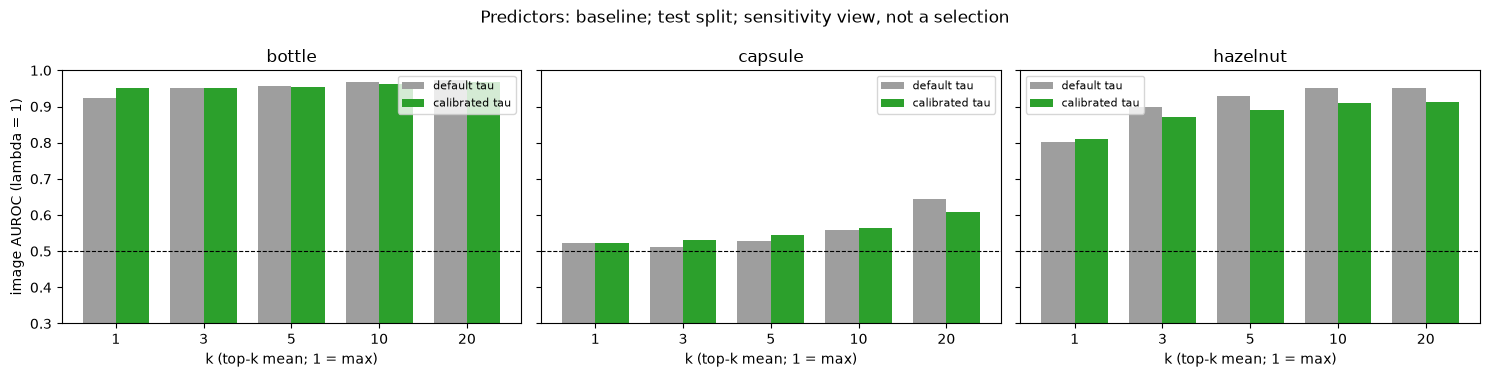

In [12]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(5 * len(CATEGORIES), 3.8), sharey=True)
width = 0.38
x = np.arange(len(K_VALUES))
for ax, category in zip(np.atleast_1d(axes), CATEGORIES):
    labels = TEST[category]['labels']
    for offset, (gate_key, color, title) in zip(
        (-width / 2, width / 2),
        (('default', '#9E9E9E', 'default tau'), (PRIMARY_KEY, '#2CA02C', 'calibrated tau')),
    ):
        values = [image_auroc(labels, combo_scores(category, gate_key, k)) for k in K_VALUES]
        ax.bar(x + offset, values, width, color=color, label=title)
    ax.axhline(0.5, color='black', linestyle='--', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([str(k) for k in K_VALUES])
    ax.set_xlabel('k (top-k mean; 1 = max)')
    ax.set_title(category)
    ax.set_ylim(0.3, 1.0)
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel('image AUROC (lambda = 1)')
fig.suptitle(f'Predictors: {PREDICTOR_SET}; test split; sensitivity view, not a selection')
fig.tight_layout()
plt.show()

## Save results

Everything is written under `results/calibration/` together with the settings and calibrated thresholds, so the run can be audited. Existing files are only replaced when `OVERWRITE = True`.

In [13]:
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
outputs = {
    'gate_calibration.csv': gate_df,
    'image_auroc_grid.csv': grid_df,
    'pixel_metrics.csv': pixel_df,
    'bootstrap_deltas.csv': boot_df,
    'decision_thresholds.csv': decision_df,
}
json_path = OUTPUT_ROOT / 'calibration_summary.json'
existing = [OUTPUT_ROOT / name for name in outputs if (OUTPUT_ROOT / name).exists()]
if json_path.exists():
    existing.append(json_path)
if existing and not OVERWRITE:
    raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')
for name, frame in outputs.items():
    frame.to_csv(OUTPUT_ROOT / name, index=False)
fig.savefig(FIGURE_ROOT / 'image_auroc_vs_k.png', dpi=150, bbox_inches='tight')
summary = {
    'predictor_set': PREDICTOR_SET,
    'encoder_sha256': ENCODER_SHA256,
    'masking_settings_yaml': MASKING_SETTINGS,
    'declared_before_test': {
        'token_quantiles': list(TOKEN_QUANTILES),
        'primary_quantile': PRIMARY_QUANTILE,
        'k_values': list(K_VALUES),
        'primary_k': PRIMARY_K,
        'lambdas': list(LAMBDAS),
        'primary_lambda': PRIMARY_LAMBDA,
        'target_fpr': TARGET_FPR,
    },
    'calibrated_tau': {c: {str(q): t for q, t in VAL[c]['taus'].items()} for c in CATEGORIES},
    'decision_thresholds': decision_thresholds,
    'validation_images': {c: len(VAL_DATASETS[c]) for c in CATEGORIES},
    'test_images': {c: len(TEST_DATASETS[c]) for c in CATEGORIES},
    'predictor_provenance_status': {c: PROVENANCE[c]['status'] for c in CATEGORIES},
    'tau_and_gate_chosen_from': 'nominal validation images only',
    'test_used_for_selection': False,
}
json_path.write_text(json.dumps(summary, indent=2, sort_keys=True), encoding='utf-8')
print(f'Saved results to {OUTPUT_ROOT}')

Saved results to c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\calibration


## What you can and cannot say

Read the paired-bootstrap table first. It is the honest scoreboard.

**You can say**
* What fraction of normal tokens/images the original gate (`tau = 0.5`) and the calibrated gate open on (Part A table). This is a validation-only fact.
* The change in image AUROC for each fix, *with its 95% interval*, for these three categories and this predictor set.
* The compute cost of the calibrated gate: masks per image and fine-trigger rate (grid and pixel tables).

**You cannot say**
* That a fix "improves" detection when its interval contains 0 (the verdict column says `inconclusive`).
* That the best-looking row of the `k` or `lambda` grid is the best setting. The grid is a sensitivity view. Choosing from it is tuning on the test set; the primary setting was declared in advance.
* Anything about the other 12 MVTec categories, other seeds, or PatchCore/MAE.

**If capsule is still at chance:** no gate or score change can help, because the predictor itself does not separate capsule defects. That needs finer masks (`coarse_size` 2 or 3), different training masks, or a different feature signal, and a retrain.

**Reproduce / re-run:** set `PREDICTOR_SET = 'augmented'` to repeat the study for the augmented predictors; change the "declared" block only before running.